In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
!pip install nltk

In [ ]:
import nltk

nltk.download("movie_reviews")
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

[nltk_data] Downloading package movie_reviews to /root/nltk_data...
[nltk_data]   Unzipping corpora/movie_reviews.zip.


In [ ]:
from nltk.corpus import movie_reviews

documents = []

for category in movie_reviews.categories():
    for fileid in movie_reviews.fileids(category):
        words = movie_reviews.words(fileid)
        text = " ".join(words)
        documents.append((text, category))

print("Total reviews:", len(documents))

Total reviews: 2000


In [ ]:
import pandas as pd

df = pd.DataFrame(documents, columns=["text", "sentiment"])

print(df.head())
print(df["sentiment"].value_counts())

                                                text sentiment
0  plot : two teen couples go to a church party ,...       neg
1  the happy bastard ' s quick movie review damn ...       neg
2  it is movies like these that make a jaded movi...       neg
3  " quest for camelot " is warner bros . ' first...       neg
4  synopsis : a mentally unstable man undergoing ...       neg
sentiment
neg    1000
pos    1000
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X = df["text"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1600
Testing samples: 400


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (1600, 10000)
Testing TF-IDF shape: (400, 10000)


In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
y_pred = model.predict(X_test_tfidf)

print(y_pred[:20])

['neg' 'neg' 'pos' 'pos' 'neg' 'pos' 'pos' 'neg' 'neg' 'pos' 'pos' 'pos'
 'neg' 'pos' 'pos' 'neg' 'neg' 'neg' 'pos' 'pos']


In [ ]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.825


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         neg       0.84      0.81      0.82       200
         pos       0.81      0.84      0.83       200

    accuracy                           0.82       400
   macro avg       0.83      0.82      0.82       400
weighted avg       0.83      0.82      0.82       400



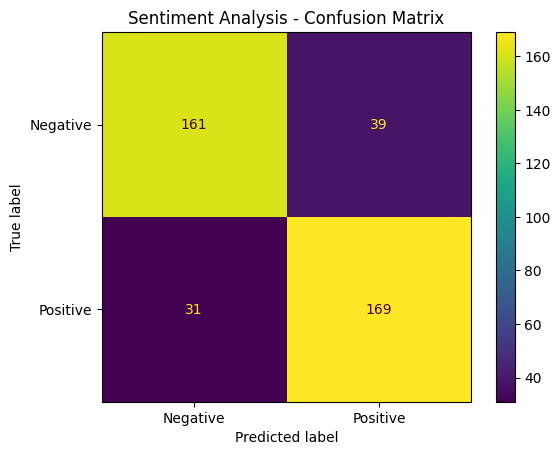

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot()

plt.title("Sentiment Analysis - Confusion Matrix")
plt.show()